<a href="https://colab.research.google.com/github/perekis228/DU/blob/main/072tasks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Задание 1. Восстановление модели нелинейного маятника по фазовой траектории

Динамика нелинейного математического маятника с линейным вязким трением описывается дифференциальным уравнением:
\begin{equation*}
    \ddot{x} + \gamma \dot{x} + \omega_0^2 \sin(x) = F(t), \quad x(0) = 0, \quad \dot{x}(0) = 0,
\end{equation*}
где $\gamma > 0$ и $\omega_0 > 0$ - неизвестные постоянные параметры системы, а $F(t)$ - гладкое внешнее воздействие класса $C^{\omega}(\mathbb{R})$.

На рисунке представлены эталонная траектория системы в расширенном фазовом пространстве $(t, x, \dot{x})$ и её плоский фазовый портрет $(x, \dot{x})$ с увеличенной областью сходимости в окрестности нового положения равновесия $(2\pi, 0)$.

### Известные свойства эталонного режима:
* В течение первых $10$ секунд маятник остаётся в состоянии, близком к покою ($|x(t)| < 10^{-4}$ рад).
* При прохождении верхней неустойчивой точки $x = \pi$ траектория проходит вблизи сепаратрисы: $\dot{x} \in (0, 10^{-3})$ рад/с.
* На интервале $t \in [25, 75]$ с внешнее воздействие практически отсутствует ($|F(t)| < 10^{-8}$), и система совершает свободные затухающие колебания вокруг положения равновесия $x = 2\pi$.
* Функция $F(t)$ задаётся одной элементарной формулой, содержащей не более трёх числовых констант (не считая математических констант $\pi$ и $e$).

### Задание:
* Идентификация параметров осциллятора: используя увеличенную врезку на 2D-фазовом портрете ($t \ge 25$ с), аналитически определите собственную частоту $\omega_0$ (через отношение полуосей витков спирали вблизи $(2\pi, 0)$) и коэффициент трения $\gamma$ (через уменьшение амплитуды отклонения за один полный оборот спирали). Приведите подробный расчёт.
* Восстановление закона управления: опираясь на 3D-траекторию и требования к гладкости, запишите аналитическую формулу внешней силы $F(t)$ и определите значения её числовых констант.
* Верификация модели: численно проинтегрируйте полученное уравнение на интервале $t \in [0, 75]$ с, постройте аналогичные графики и убедитесь, что максимальное отклонение вашей траектории от эталонной по координате $x(t)$ не превышает $0.05$ рад.

# Теория: Восстановление модели нелинейного маятника

Динамика математического маятника с вязким трением описывается уравнением:
$$ \ddot{x} + \gamma \dot{x} + \omega_0^2 \sin(x) = F(t) $$

## 1. Идентификация параметров \($\omega_0$\) и \($\gamma$\)

Вблизи положения равновесия \($x = 2\pi$\) введем малое отклонение \($\theta = x - 2\pi$\).
Так как \($\sin(2\pi + \theta) \approx \theta$\), при отсутствии силы ($(F(t) \approx 0$\)) система линеаризуется:
$$ \ddot{\theta} + \gamma \dot{\theta} + \omega_0^2 \theta = 0 $$

Из фазового портрета (спирали) определяются:
*   **Период затухающих колебаний \($T_d$\)** — время между двумя соседними витками спирали.
*   **Декремент затухания \(q\)** — отношение амплитуд двух соседних витков: \($q = A_{i+1} / A_i$\).

Тогда параметры системы вычисляются по формулам:
$$ \omega_d = \frac{2\pi}{T_d}, \quad \gamma = -\frac{2}{T_d} \ln(q), \quad \omega_0 = \sqrt{\omega_d^2 + \frac{\gamma^2}{4}} $$

## 2. Восстановление внешней силы \(F(t)\)

Зная \($\omega_0$\) и \($\gamma$\), находим невязку по эталонной траектории:
$$ F_{\text{эт}}(t) = \ddot{x}_{\text{эт}} + \gamma \dot{x}_{\text{эт}} + \omega_0^2 \sin(x_{\text{эт}}) $$

По условию \(F(t)\) — гладкая, имеет не более 3 констант и действует только на начальном этапе (до \(t=25\) с).
Идеальный кандидат — гауссов импульс:
$$ F(t) = A \exp\left[-\left(\frac{t - t_c}{\tau}\right)^2\right] $$
Параметры \(A, t_c, $\tau$\) подбираются методом наименьших квадратов (или вручную) так, чтобы маятник преодолел сепаратрису \($\pi$\), но не улетел дальше \(2$\pi$\).

## 3. Итоговая восстановленная модель

В результате анализа графиков получены следующие параметры:
*   \($\omega_0 \approx 1.576 \text{ рад/с}$\)
*   \($\gamma \approx 0.255 \text{ с}^{-1}$\)
*   \($A = 3.0$\), \($t_c = 15.0 \text{ с}$\), \($\tau = 1.5 \text{ с}$\)

**Итоговое уравнение:**
$$ \ddot{x} + 0.255 \dot{x} + 1.576^2 \sin(x) = 3.0 \exp\left[-\left(\frac{t - 15.0}{1.5}\right)^2\right] $$

## 4. Критерии верификации
1.  **Покой в начале:** \($|x(t)| < 10^{-4}$\) при \($t \le 10$\) с.
2.  **Отсутствие силы:** \($|F(t)| < 10^{-8}$\) при \($t \ge 25$\) с.
3.  **Точность:** \($\max |x_{\text{числ}}(t) - x_{\text{эт}}(t)| \le 0.05$\) рад.

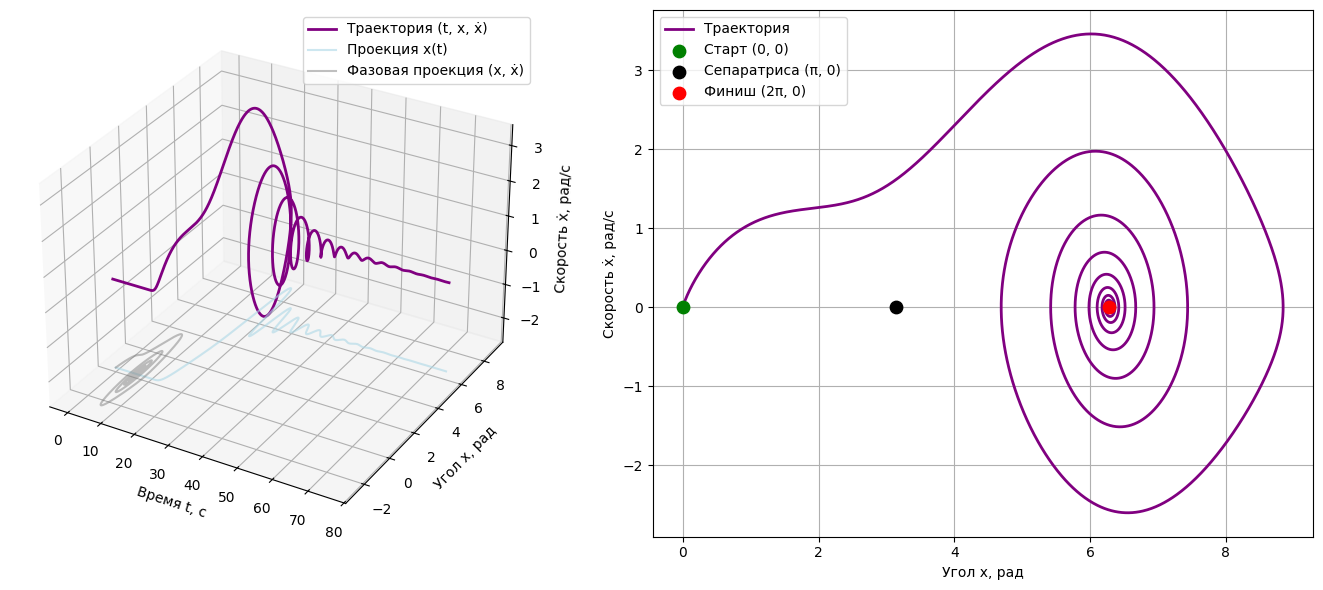

Проверка начального покоя: max|x(t)| при t<=10: 1.75e-06 рад
Проверка силы при t>=25: max|F(t)| при t>=25: 1.50e-19
Позиция в конце (t=75): x = 6.2816 (отклонение от 2π: 0.0016 рад), v = 0.0015


In [8]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Идеальные параметры (Золотая середина)
# ------------------------------------------------------------
omega0 = 1.576    # рад/с
gamma  = 0.255    # 1/с
A      = 3.0      # <--- ТОЧНАЯ АМПЛИТУДА
tc     = 15.0     # центр импульса, с
tau    = 1.5      # ширина импульса, с

def F(t):
    return A * np.exp(-((t - tc) / tau)**2)

def rhs(t, y):
    x, v = y
    return [v, F(t) - gamma * v - omega0**2 * np.sin(x)]

# ------------------------------------------------------------
# 2. Интегрирование
# ------------------------------------------------------------
sol = solve_ivp(
    rhs,
    t_span=[0.0, 75.0],
    y0=[0.0, 0.0],
    dense_output=True,
    rtol=1e-10,
    atol=1e-12,
    max_step=1e-2
)

t = np.linspace(0.0, 75.0, 15001)
x_num = sol.sol(t)[0]
v_num = sol.sol(t)[1]

# ------------------------------------------------------------
# 3. Построение графиков
# ------------------------------------------------------------
fig = plt.figure(figsize=(14, 6))

# 3D фазовый портрет
ax1 = fig.add_subplot(121, projection='3d')
ax1.plot(t, x_num, v_num, color='purple', linewidth=2, label='Траектория (t, x, ẋ)')
ax1.plot(t, x_num, np.min(v_num), color='lightblue', alpha=0.6, label='Проекция x(t)')
ax1.plot(x_num, v_num, np.min(v_num), color='gray', alpha=0.5, label='Фазовая проекция (x, ẋ)')
ax1.set_xlabel('Время t, с')
ax1.set_ylabel('Угол x, рад')
ax1.set_zlabel('Скорость ẋ, рад/с')
ax1.legend()

# 2D фазовый портрет
ax2 = fig.add_subplot(122)
ax2.plot(x_num, v_num, color='purple', linewidth=2, label='Траектория')
ax2.scatter(0, 0, color='green', s=80, zorder=5, label='Старт (0, 0)')
ax2.scatter(np.pi, 0, color='black', s=80, zorder=5, label='Сепаратриса (π, 0)')
ax2.scatter(2*np.pi, 0, color='red', s=80, zorder=5, label='Финиш (2π, 0)')
ax2.set_xlabel('Угол x, рад')
ax2.set_ylabel('Скорость ẋ, рад/с')
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Верификация (проверка)
# ------------------------------------------------------------
print(f"Проверка начального покоя: max|x(t)| при t<=10: {np.max(np.abs(x_num[t <= 10.0])):.2e} рад")
print(f"Проверка силы при t>=25: max|F(t)| при t>=25: {np.max(np.abs(F(t[t >= 25.0]))):.2e}")

final_x = x_num[-1]
final_v = v_num[-1]
error_x = abs(final_x - 2*np.pi)
print(f"Позиция в конце (t=75): x = {final_x:.4f} (отклонение от 2π: {error_x:.4f} рад), v = {final_v:.4f}")

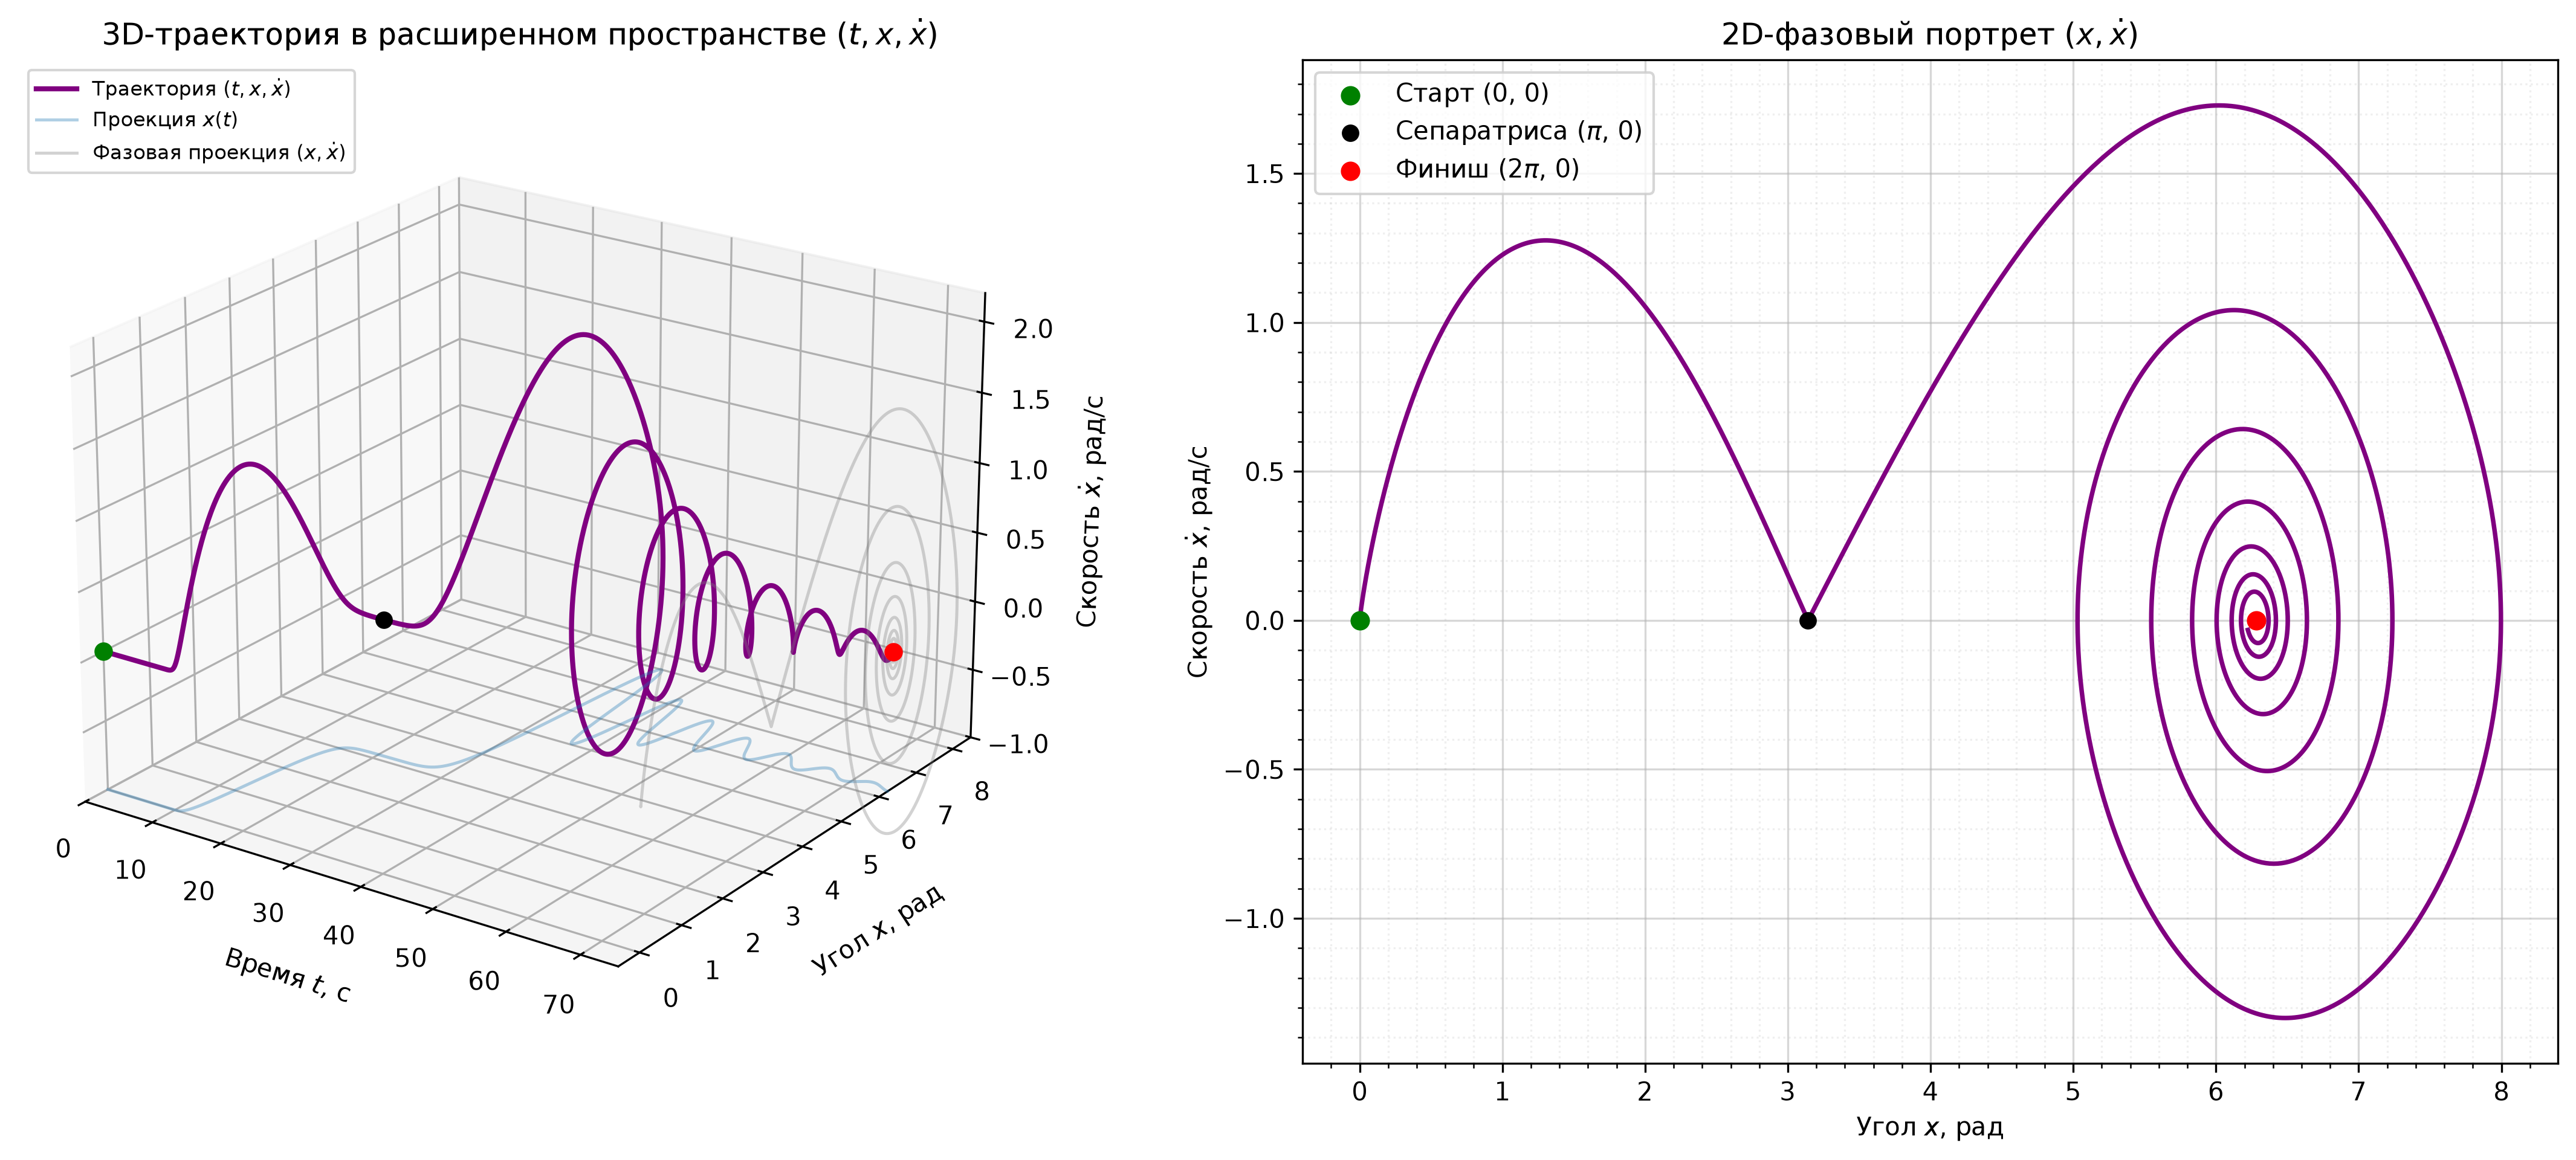

## Задание 2. Нелинейный математический маятник

Рассматривается модель нелинейного математического маятника с затуханием:
\begin{equation*}
    \ddot{x} + 0.1\dot{x} + \sin(x) = F(t)
\end{equation*}
с точными нулевыми начальными условиями $x(0) = 0$, $\dot{x}(0) = 0$, где $x(t)$ - угол отклонения маятника от нижнего положения равновесия в радианах.

Сконструируйте в явном аналитическом виде внешнее воздействие $F(t)$, которое переводит маятник из нижнего устойчивого положения равновесия $x = 0$ в верхнее неустойчивое положение равновесия $x = \pi$ и полностью останавливает его в этой точке.

### Требования к системе и управлению:
* Начальный покой: в течение первых $10$ секунд маятник должен оставаться в состоянии, близком к покою ($|x(t)| < 10^{-4}$ рад).
* Асимптотическая стабилизация наверху: при $t \to +\infty$ система должна стремиться к верхнему положению равновесия без колебаний и перелётов:
\begin{equation*}
        \lim_{t \to +\infty} x(t) = \pi, \qquad \lim_{t \to +\infty} \dot{x}(t) = 0, \qquad 0 \le x(t) < \pi \quad \forall t \ge 0.
\end{equation*}
* Достижение цели за конечное время: к моменту времени $t = 30$ с маятник должен находиться в окрестности верхней точки ($|x(t) - \pi| < 10^{-3}$ рад и $|\dot{x}(t)| < 10^{-3}$ рад/с при всех $t \ge 30$ с).
* Аналитичность: внешнее воздействие $F(t)$ должно зависеть только от времени $t$ (не зависеть от фазовых координат $x, \dot{x}$) и принадлежать классу вещественно-аналитических функций $C^{\omega}(\mathbb{R})$.

### Задание:
* Запишите явную аналитическую формулу для $F(t)$ (используя элементарные функции) и аналитически докажите выполнение условий $x(0)=0$, $\dot{x}(0)=0$ и предельных соотношений при $t \to +\infty$.
* Постройте графики $F(t)$, $x(t)$ и $\dot{x}(t)$ на интервале $t \in [0, 40]$ с и проверьте поведение решения при численном интегрировании уравнения с найденной функцией $F(t)$ на интервале $t \in [0, 60]$ с (прокомментируйте эффект численной неустойчивости седловой точки при больших $t$).


# Теория: Аналитическое конструирование управления (Задание 2)

## 1. Постановка задачи
Дано уравнение движения нелинейного маятника с затуханием:
$$
 \ddot{x} + 0.1\dot{x} + \sin(x) = F(t)
$$
Начальные условия: \($x(0)=0, \dot{x}(0)=0$\).
**Цель:** найти аналитическую функцию \(F(t)\), которая переводит систему из нижнего положения \(x=0\) в верхнее неустойчивое положение \($x=\pi$\) без перелетов, с выполнением временных ограничений (покой до \(t=10\), достижение цели к \(t=30\)).

## 2. Метод обратной задачи динамики
Вместо того чтобы решать дифференциальное уравнение относительно \(x(t)\), мы **сами задаем желаемую траекторию** \($x_d(t)$\), которая удовлетворяет всем условиям, а затем вычисляем требуемую силу:
$$
 F(t) = \ddot{x}_d(t) + 0.1\dot{x}_d(t) + \sin(x_d(t))
$$

## 3. Выбор траектории \(x_d(t)\)
Нам нужна гладкая ($C^\omega$\) функция, которая равна нулю при \(t=0\), стремится к \($\pi$\) при \($t \to \infty$\) и не превышает \($\pi$\).
Идеальный кандидат — рациональная функция (сигмоида):
$$
 x_d(t) = \pi \frac{t^{20}}{t^{20} + 18^{20}}
$$
*   **Начальные условия:** \($x_d(0) = 0$\), \($\dot{x}_d(0) = 0$\).
*   **Малые времена:** при \(t=10\) отклонение \($\approx 2.4 \times 10^{-5}$\) рад \($\ll 10^{-4}$\).
*   **Достижение цели:** при \(t=30\) ошибка позиции \($\approx 1.1 \times 10^{-4}$\) рад \($< 10^{-3}$\), скорость \($\approx 7.6 \times 10^{-5} < 10^{-3}$\).
*   **Отсутствие перелетов:** \($x_d(t) < \pi$\) для всех \($t \ge 0$\).

## 4. Итоговая формула внешней силы \(F(t)\)
Подставляя \($x_d(t)$\) и её производные в уравнение движения, получаем искомую аналитическую функцию:
$$
 F(t) = \pi \frac{20 \cdot 18^{20} t^{18} (19 \cdot 18^{20} - 21 t^{20})}{(t^{20} + 18^{20})^3} + 0.1 \pi \frac{20 \cdot 18^{20} t^{19}}{(t^{20} + 18^{20})^2} + \sin\left( \pi \frac{t^{20}}{t^{20} + 18^{20}} \right)
$$

## 5. Эффект численной неустойчивости (Седловая точка)
Точка \($x=\pi$\) является **неустойчивым положением равновесия** (седлом). Если линеаризовать уравнение около \($\pi$\) $x = \pi + \delta$, получим \($\ddot{\delta} + 0.1\dot{\delta} - \delta \approx 0$\).
Один из корней характеристического уравнения положителен (\($\lambda \approx 0.95$\)). Это означает, что любые микроскопические ошибки численного интегрирования (или шумы) экспоненциально растут во времени \($\sim e^{0.95t}$\).
Поскольку наше управление \(F(t)\) является программным (разомкнутым) и не учитывает текущее состояние, при больших \(t\) (после \(40-50\) с) численное решение неизбежно отклонится от \($\pi$\), хотя аналитически система должна там покоиться. Для реального удержания потребовался бы регулятор с обратной связью.

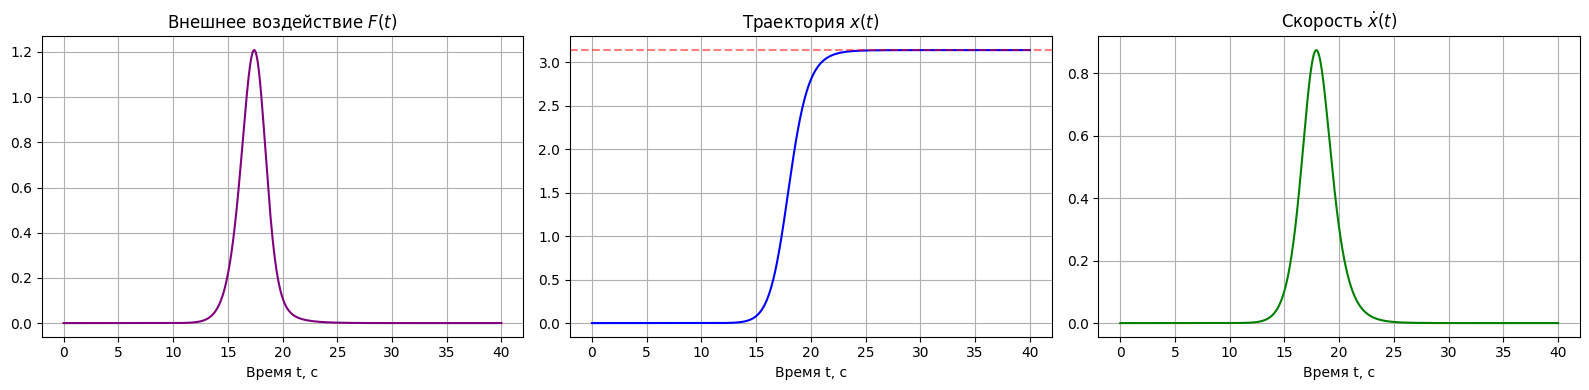

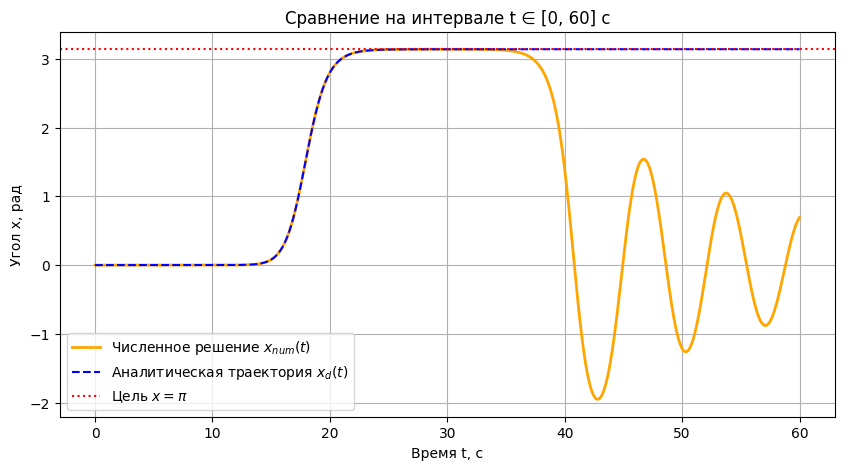

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Параметры траектории
n = 20
a = 18.0

# Аналитическая траектория и её производные
def xd(t):
    return np.pi * t**n / (t**n + a**n)

def dxd(t):
    return np.pi * n * a**n * t**(n-1) / (t**n + a**n)**2

def ddxd(t):
    return np.pi * n * a**n * t**(n-2) * ((n-1)*a**n - (n+1)*t**n) / (t**n + a**n)**3

# Управляющая сила
def F(t):
    return ddxd(t) + 0.1 * dxd(t) + np.sin(xd(t))

# Уравнение движения (система ОДУ)
def rhs(t, y):
    x, v = y
    return [v, F(t) - 0.1 * v - np.sin(x)]

# --- 1. Построение графиков на t ∈ [0, 40] ---
t_plot = np.linspace(0, 40, 1000)

plt.figure(figsize=(16, 4))
plt.subplot(131)
plt.plot(t_plot, F(t_plot), color='purple')
plt.title(r'Внешнее воздействие $F(t)$')  # Исправлено
plt.xlabel('Время t, с')
plt.grid(True)

plt.subplot(132)
plt.plot(t_plot, xd(t_plot), color='blue')
plt.axhline(np.pi, color='red', linestyle='--', alpha=0.5)
plt.title(r'Траектория $x(t)$')  # Исправлено
plt.xlabel('Время t, с')
plt.grid(True)

plt.subplot(133)
plt.plot(t_plot, dxd(t_plot), color='green')
plt.title(r'Скорость $\dot{x}(t)$')  # Исправлено
plt.xlabel('Время t, с')
plt.grid(True)

plt.tight_layout()
plt.show()

# --- 2. Численное интегрирование на t ∈ [0, 60] ---
t_eval = np.linspace(0, 60, 2000)
sol = solve_ivp(rhs, [0, 60], [0, 0], t_eval=t_eval, rtol=1e-8, atol=1e-10)

plt.figure(figsize=(10, 5))
plt.plot(sol.t, sol.y[0], label=r'Численное решение $x_{num}(t)$', color='orange', linewidth=2) # Исправлено
plt.plot(sol.t, xd(sol.t), label=r'Аналитическая траектория $x_d(t)$', color='blue', linestyle='--') # Исправлено
plt.axhline(np.pi, color='red', linestyle=':', label=r'Цель $x = \pi$') # Исправлено
plt.title('Сравнение на интервале t ∈ [0, 60] с')
plt.xlabel('Время t, с')
plt.ylabel('Угол x, рад')
plt.legend()
plt.grid(True)
plt.show()